In [1]:
%pip install ISLP statsmodels

INFO: pip is looking at multiple versions of islp to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 12.4 MB/s  0:00:00 eta 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 9.0 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 11.7 MB/s  0:00:00eta 0:00:01
Using cached numpy-2.5.5-cp315-cp315-macosx_14_0_arm64.whl (5.5 MB)
   ━━━━━━━━━

In [2]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots

Matplotlib is building the font cache; this may take a moment.


Throughout this lab we will introduce new functions and libraries. However,
we will import them here to emphasize these are the new code objects in
this lab. Keeping imports near the top of a notebook makes the code more
readable, since scanning the first few lines tells us what libraries are used.

In [3]:
import statsmodels.api as sm

We will provide relevant details about the functions below as they are
needed.
Besides importing whole modules, it is also possible to import only a
few items from a given module. This will help keep the namespace clean. namespace
We will use a few specific objects from the statsmodels package which we statsmodels
import here.

In [4]:
from statsmodels.stats.outliers_influence \
import variance_inflation_factor as VIF
from statsmodels.stats.anova import anova_lm

As one of the import statements above is quite a long line, we inserted a
line break \ to ease readability.
We will also use some functions written for the labs in this book in the
ISLP package.

In [5]:
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
summarize,
poly)

In [6]:
dir()

['In',
 'MS',
 'Out',
 'VIF',
 '_',
 '__',
 '___',
 '__builtin__',
 '__builtins__',
 '__doc__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 '__vsc_ipynb_file__',
 '_dh',
 '_exit_code',
 '_i',
 '_i1',
 '_i2',
 '_i3',
 '_i4',
 '_i5',
 '_i6',
 '_ih',
 '_ii',
 '_iii',
 '_oh',
 'anova_lm',
 'exit',
 'get_ipython',
 'load_data',
 'np',
 'open',
 'pd',
 'poly',
 'quit',
 'sm',
 'subplots',
 'summarize']

This shows you everything that Python can find at the top level. There
are certain objects like __builtins__ that contain references to built-in
functions like print().
Every python object has its own notion of namespace, also accessible
with dir(). This will include both the attributes of the object as well as
any methods associated with it. For instance, we see 'sum' in the listing
for an array.

In [7]:
A=np.array([3,5,11])
dir(A)

['T',
 '__abs__',
 '__add__',
 '__and__',
 '__array__',
 '__array_finalize__',
 '__array_function__',
 '__array_interface__',
 '__array_namespace__',
 '__array_priority__',
 '__array_struct__',
 '__array_ufunc__',
 '__array_wrap__',
 '__bool__',
 '__buffer__',
 '__class__',
 '__class_getitem__',
 '__complex__',
 '__contains__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__delitem__',
 '__dir__',
 '__divmod__',
 '__dlpack__',
 '__dlpack_device__',
 '__doc__',
 '__eq__',
 '__float__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__iand__',
 '__ifloordiv__',
 '__ilshift__',
 '__imatmul__',
 '__imod__',
 '__imul__',
 '__index__',
 '__init__',
 '__init_subclass__',
 '__int__',
 '__invert__',
 '__ior__',
 '__ipow__',
 '__irshift__',
 '__isub__',
 '__iter__',
 '__itruediv__',
 '__ixor__',
 '__le__',
 '__len__',
 '__lshift__',
 '__lt__',
 '__matmul__',
 '__mod__',
 '__mul__',
 '__ne__',
 '__neg__',


In [8]:
A.sum()

np.int64(19)

3.6.2 Simple Linear Regression
In this section we will construct model matrices (also called design matri-
ces) using the ModelSpec() transform from ISLP.models.
We will use the Boston housing data set, which is contained in the ISLP
package. The Boston dataset records medv (median house value) for 506
neighborhoods around Boston. We will build a regression model to pre-
dict medv using 13 predictors such as rmvar (average number of rooms per
house), age (proportion of owner-occupied units built prior to 1940), and
lstat (percent of households with low socioeconomic status). We will use
statsmodels for this task, a Python package that implements several com-
monly used regression methods.
We have included a simple loading function load_data() in the ISLP pack- age:

In [9]:
Boston = load_data('Boston')
Boston.columns

Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'lstat', 'medv'],
      dtype='object')

In [10]:
X=pd.DataFrame({'intercept':np.ones(Boston.shape[0]),
'lstat':Boston['lstat']})
X[:4]

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94


In [11]:
y=Boston['medv']
model = sm.OLS(y, X)
results = model.fit()

In [12]:
summarize(results)

,coef,std err,t,P>|t|
intercept,34.5538,0.563,61.415,0.0
lstat,-0.9500,0.039,-24.528,0.0


In [13]:
design = MS(['lstat'])
design = design.fit(Boston)
X=design.transform(Boston)
X[:4]

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94


In [14]:
design = MS(['lstat'])
X=design.fit_transform(Boston)
X[:4]

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94


In [15]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   medv   R-squared:                       0.544
Model:                            OLS   Adj. R-squared:                  0.543
Method:                 Least Squares   F-statistic:                     601.6
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           5.08e-88
Time:                        13:53:31   Log-Likelihood:                -1641.5
No. Observations:                 506   AIC:                             3287.
Df Residuals:                     504   BIC:                             3295.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     34.5538      0.563     61.415      0.000      33.448      35.659
lstat         -0.9500      0.039    -24.528      0.000      -1.026      -0.874
==============================================================================
Omnibus:                      137.043   Durbin-Watson:                   0.892
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              291.373
Skew:                           1.453   Prob(JB):                     5.36e-64
Kurtosis:                       5.319   Cond. No.                         29.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [16]:
results.params

intercept    34.553841
lstat        -0.950049
dtype: float64

In [17]:
new_df = pd.DataFrame({'lstat':[5, 10, 15]})
newX = design.transform(new_df)
newX

,intercept,lstat
0,1.0,5
1,1.0,10
2,1.0,15


In [18]:
new_predictions = results.get_prediction(newX);
new_predictions.predicted_mean

array([29.80359411, 25.05334734, 20.30310057])

In [19]:
new_predictions.conf_int(alpha=0.05)

array([[29.00741194, 30.59977628],
       [24.47413202, 25.63256267],
       [19.73158815, 20.87461299]])

In [20]:
new_predictions.conf_int(obs=True, alpha=0.05)

array([[17.56567478, 42.04151344],
       [12.82762635, 37.27906833],
       [ 8.0777421 , 32.52845905]])

Defining Functions
While there is a function within the ISLP package that adds a line to an
existing plot, we take this opportunity to define our first function to do so.

In [22]:
def abline(ax, b, m):
    xlim = ax.get_xlim()
    ylim = [m * xlim[0] + b, m * xlim[1] + b]
    ax.plot(xlim, ylim)

Text(0, 0.5, 'medv')

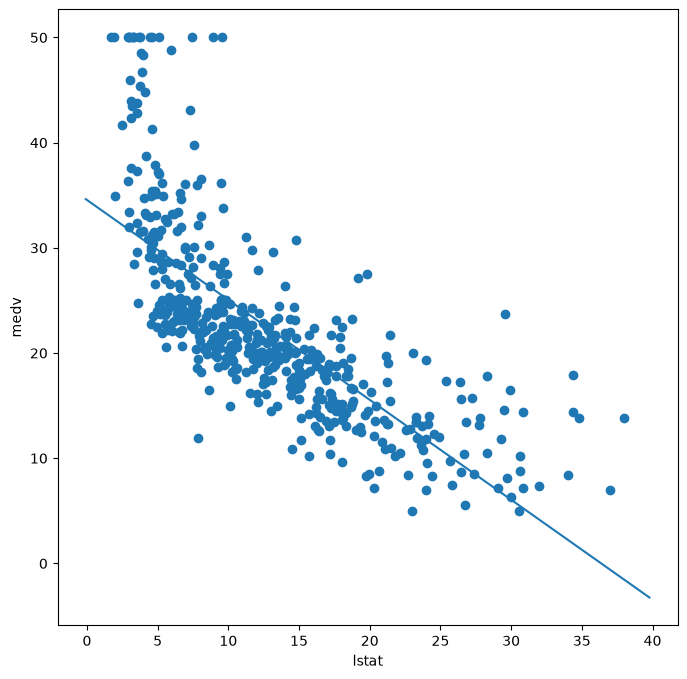

In [23]:
fig, ax = subplots(figsize=(8, 8))

ax.scatter(Boston['lstat'], Boston['medv'])
abline(ax, results.params.iloc[0], results.params.iloc[1])

ax.set_xlabel('lstat')
ax.set_ylabel('medv')

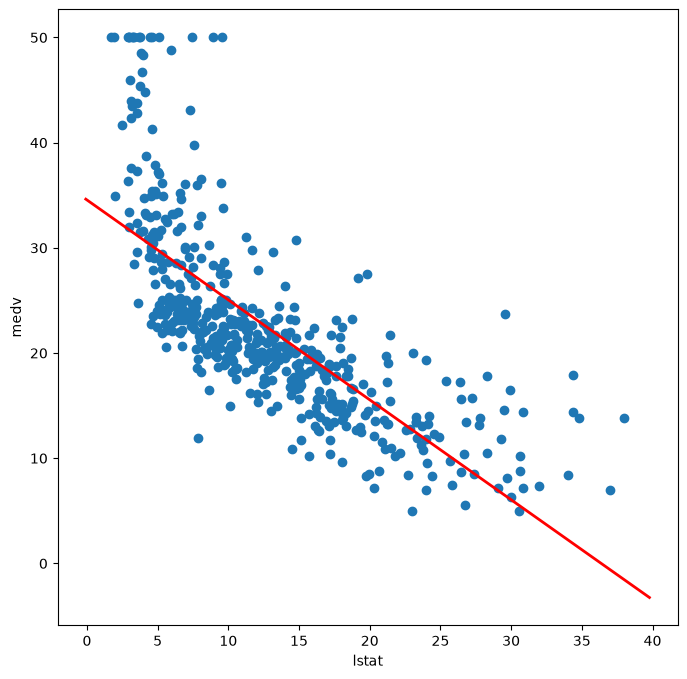

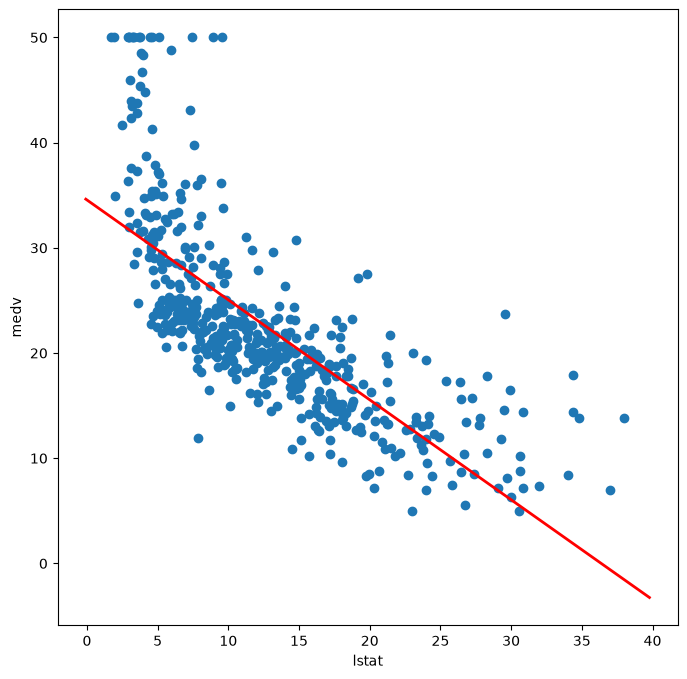

In [24]:
def abline(ax, b, m, *args, **kwargs):
    """Add a line with slope m and intercept b to ax."""
    xlim = ax.get_xlim()
    ylim = [m * xlim[0] + b, m * xlim[1] + b]
    ax.plot(xlim, ylim, *args, **kwargs)


# Fit the regression model
X = MS(['lstat']).fit_transform(Boston)
y = Boston['medv']
results = sm.OLS(y, X).fit()

# Plot the data and fitted regression line
fig, ax = subplots(figsize=(8, 8))
ax.scatter(Boston['lstat'], Boston['medv'])

abline(
    ax,
    results.params['intercept'],
    results.params['lstat'],
    color='red',
    linewidth=2
)

ax.set_xlabel('lstat')
ax.set_ylabel('medv')
fig

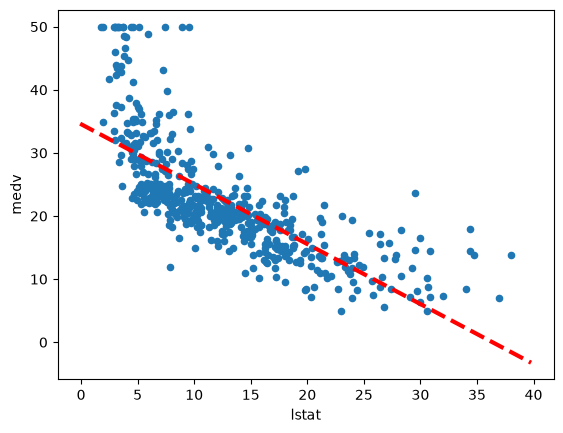

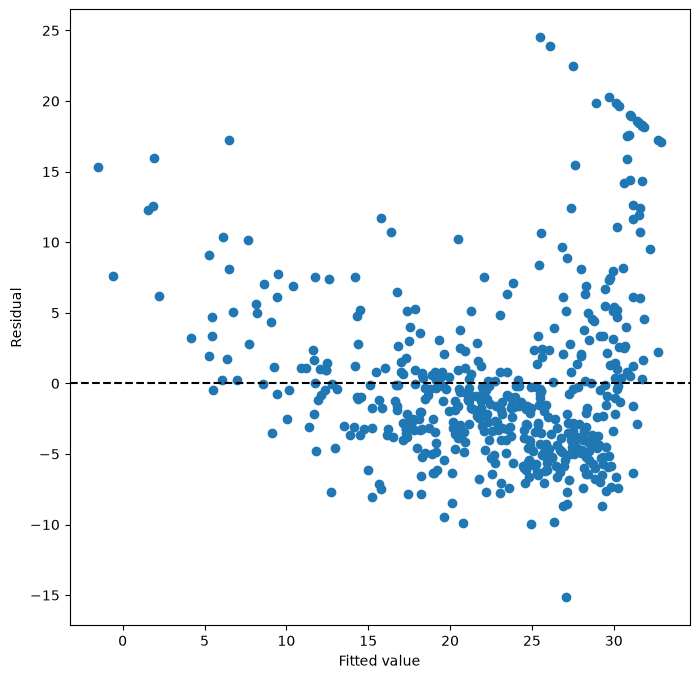

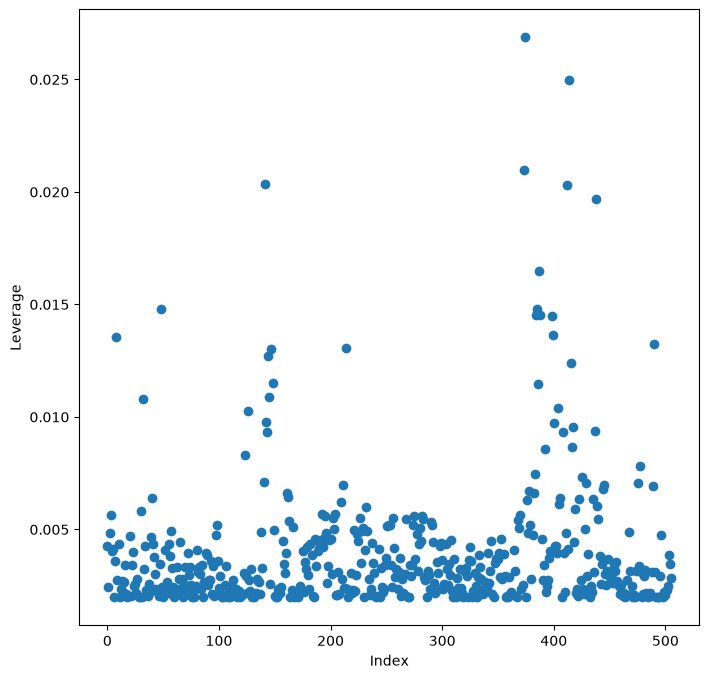

Index with highest leverage: 374


,coef,std err,t,P>|t|
intercept,33.2228,0.731,45.458,0.000
lstat,-1.0321,0.048,-21.416,0.000
age,0.0345,0.012,2.826,0.005


Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'lstat'],
      dtype='object')

,coef,std err,t,P>|t|
intercept,41.6173,4.936,8.431,0.000
crim,-0.1214,0.033,-3.678,0.000
zn,0.0470,0.014,3.384,0.001
indus,0.0135,0.062,0.217,0.829
chas,2.8400,0.870,3.264,0.001
nox,-18.7580,3.851,-4.870,0.000
rm,3.6581,0.420,8.705,0.000
age,0.0036,0.013,0.271,0.787
dis,-1.4908,0.202,-7.394,0.000
rad,0.2894,0.067,4.325,0.000


,coef,std err,t,P>|t|
intercept,41.5251,4.920,8.441,0.000
crim,-0.1214,0.033,-3.683,0.000
zn,0.0465,0.014,3.379,0.001
indus,0.0135,0.062,0.217,0.829
chas,2.8528,0.868,3.287,0.001
nox,-18.4851,3.714,-4.978,0.000
rm,3.6811,0.411,8.951,0.000
dis,-1.5068,0.193,-7.825,0.000
rad,0.2879,0.067,4.322,0.000
tax,-0.0127,0.004,-3.333,0.001


R-squared: 0.7343070437613077
Residual standard error: 4.798034335596366


,vif
crim,1.767486
zn,2.298459
indus,3.987181
chas,1.071168
nox,4.369093
rm,1.912532
age,3.088232
dis,3.954037
rad,7.445301
tax,9.002158


,coef,std err,t,P>|t|
intercept,36.0885,1.470,24.553,0.000
lstat,-1.3921,0.167,-8.313,0.000
age,-0.0007,0.020,-0.036,0.971
lstat:age,0.0042,0.002,2.244,0.025


,coef,std err,t,P>|t|
intercept,17.7151,0.781,22.681,0.0
"poly(lstat, degree=2)[0]",-179.2279,6.733,-26.620,0.0
"poly(lstat, degree=2)[1]",72.9908,5.482,13.315,0.0
age,0.0703,0.011,6.471,0.0


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,503.0,19168.128609,0.0,NaN,NaN,NaN
1,502.0,14165.613251,1.0,5002.515357,177.278785,7.468491e-35


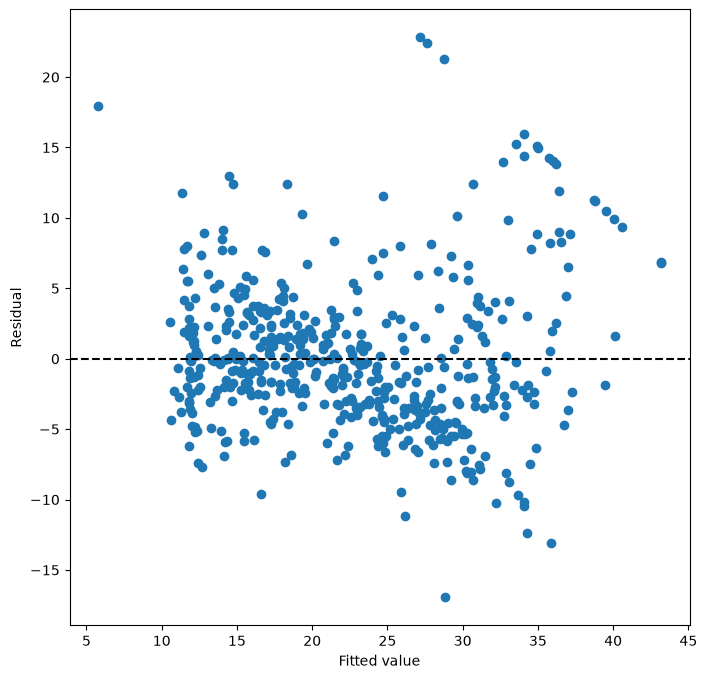

Index(['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price',
       'ShelveLoc', 'Age', 'Education', 'Urban', 'US'],
      dtype='object')

,coef,std err,t,P>|t|
intercept,6.5756,1.009,6.519,0.000
CompPrice,0.0929,0.004,22.567,0.000
Income,0.0109,0.003,4.183,0.000
Advertising,0.0702,0.023,3.107,0.002
Population,0.0002,0.000,0.433,0.665
Price,-0.1008,0.007,-13.549,0.000
ShelveLoc[Good],4.8487,0.153,31.724,0.000
ShelveLoc[Medium],1.9533,0.126,15.531,0.000
Age,-0.0579,0.016,-3.633,0.000
Education,-0.0209,0.020,-1.063,0.288


In [26]:
import matplotlib.pyplot as plt
# Scatterplot with fitted regression line
ax = Boston.plot.scatter('lstat', 'medv')
abline(
    ax,
    results.params.iloc[0],
    results.params.iloc[1],
    'r--',
    linewidth=3
)
plt.show()


# Residual plot for simple linear regression
fig, ax = subplots(figsize=(8, 8))
ax.scatter(results.fittedvalues, results.resid)
ax.set_xlabel('Fitted value')
ax.set_ylabel('Residual')
ax.axhline(0, c='k', ls='--')
plt.show()


# Leverage plot
infl = results.get_influence()

fig, ax = subplots(figsize=(8, 8))
ax.scatter(np.arange(X.shape[0]), infl.hat_matrix_diag)
ax.set_xlabel('Index')
ax.set_ylabel('Leverage')
plt.show()

print('Index with highest leverage:', np.argmax(infl.hat_matrix_diag))


# Multiple linear regression using lstat and age
X = MS(['lstat', 'age']).fit_transform(Boston)
model1 = sm.OLS(y, X)
results1 = model1.fit()
display(summarize(results1))


# Multiple linear regression using all predictors
terms = Boston.columns.drop('medv')
display(terms)

X = MS(terms).fit_transform(Boston)
model = sm.OLS(y, X)
results = model.fit()
display(summarize(results))


# Multiple linear regression excluding age
minus_age = Boston.columns.drop(['medv', 'age'])
Xma = MS(minus_age).fit_transform(Boston)
model1 = sm.OLS(y, Xma)
display(summarize(model1.fit()))


# Goodness of fit for the model using all predictors
print('R-squared:', results.rsquared)
print('Residual standard error:', np.sqrt(results.scale))


# Variance inflation factors for all predictors
vals = [
    VIF(X, i)
    for i in range(1, X.shape[1])
]

vif = pd.DataFrame(
    {'vif': vals},
    index=X.columns[1:]
)
display(vif)


# Equivalent calculation using a for loop
vals = []
for i in range(1, X.values.shape[1]):
    vals.append(VIF(X.values, i))


# Regression with an interaction between lstat and age
X = MS([
    'lstat',
    'age',
    ('lstat', 'age')
]).fit_transform(Boston)

model2 = sm.OLS(y, X)
display(summarize(model2.fit()))


# Regression with a quadratic term in lstat
X = MS([
    poly('lstat', degree=2),
    'age'
]).fit_transform(Boston)

model3 = sm.OLS(y, X)
results3 = model3.fit()
display(summarize(results3))


# Compare the linear and quadratic models
display(anova_lm(results1, results3))


# Residual plot for the quadratic model
fig, ax = subplots(figsize=(8, 8))
ax.scatter(results3.fittedvalues, results3.resid)
ax.set_xlabel('Fitted value')
ax.set_ylabel('Residual')
ax.axhline(0, c='k', ls='--')
plt.show()


# Load Carseats data
Carseats = load_data('Carseats')
display(Carseats.columns)


# Fit a model with qualitative predictors and interaction terms
allvars = list(Carseats.columns.drop('Sales'))
y = Carseats['Sales']

final = allvars + [
    ('Income', 'Advertising'),
    ('Price', 'Age')
]

X = MS(final).fit_transform(Carseats)
model = sm.OLS(y, X)
display(summarize(model.fit()))